# Oracle and objective

What a verdict and a safety margin do and do not tell a search.

The live cells are small and take a few minutes on a laptop CPU. Campaign-scale numbers are read from `results/v2/summary.json`. Everything here measures injected noise in one simple simulator setup, so none of it says anything about a real vehicle.

**Matching assessment**

- [Oracle and objective](https://niharvaghela1995.github.io/masters-thesis/assessments/s06_oracle_objective.html)
- [Tail-risk gap](https://niharvaghela1995.github.io/masters-thesis/assessments/s06b_tail_risk_gap.html)

In [1]:
import json, sys, tempfile, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src").exists() else ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from stp import runner, scenario as S
from stp.v2.config import CANDIDATES, LEVELS, cfg_for
from stp.v2 import rules as RL
SPACE = CANDIDATES["A"]
SUMMARY = json.load(open(ROOT / "results/v2/summary.json"))
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
BLUE, ORANGE = "#2a78d6", "#eb6834"
def along(speeds, k1=0.012, k2=-0.004, gust=0.8):
    return [S.Params(float(v), k1, k2, gust) for v in speeds]
def reruns(p, n, level="medium", base=0):
    return [runner.run(p, base + i, LEVELS[level]) for i in range(n)]


## S06-P05: binary outcomes are hard to search

The pass or fail verdict is flat almost everywhere. The margin it is derived from has a slope a search can follow.

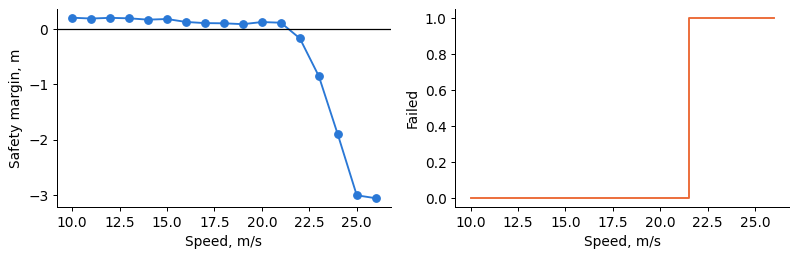

In [2]:
speeds = np.linspace(10, 26, 17)
rs = [runner.run(p, 1, LEVELS["low"]) for p in along(speeds)]
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(speeds, [r["margin"] for r in rs], "o-", color=BLUE); ax[0].axhline(0, color="k", lw=1); ax[0].set_xlabel("Speed, m/s"); ax[0].set_ylabel("Safety margin, m")
ax[1].step(speeds, [int(r["failed"]) for r in rs], color=ORANGE, where="mid"); ax[1].set_xlabel("Speed, m/s"); ax[1].set_ylabel("Failed"); plt.tight_layout(); plt.show()

## S06-P02: a threshold decides which scenarios count

A failure is a margin below 0. Moving that threshold changes the failure set, and the overlap below measures how much.

In [3]:
g = np.random.default_rng(3); X = g.uniform(SPACE["xl"], SPACE["xu"], (400, 4))
t = time.time(); m = np.array([runner.run(S.Params(*map(float, x)), i, LEVELS["medium"])["margin"] for i, x in enumerate(X)]); print(f"{time.time() - t:.0f} s")
base = m < 0
for th in (-0.2, -0.1, 0.0, 0.1, 0.2):
    s = m < th; print(f"margin < {th:+.1f}: {s.mean():.3f} of runs, overlap with margin < 0: {(s & base).sum() / max((s | base).sum(), 1):.2f}")

28 s
margin < -0.2: 0.205 of runs, overlap with margin < 0: 0.91
margin < -0.1: 0.207 of runs, overlap with margin < 0: 0.92
margin < +0.0: 0.225 of runs, overlap with margin < 0: 1.00
margin < +0.1: 0.295 of runs, overlap with margin < 0: 0.76
margin < +0.2: 0.380 of runs, overlap with margin < 0: 0.59


## S06-P01: does the objective change which scenarios look worst?

A first look at G2: 15 scenarios near the limit, 20 reruns each, ranked by the mean margin, the worst run, and the mean of the worst 4 runs (a tail measure at α = 0.8). This is a small demonstration, not a G2 result.

In [4]:
from scipy.stats import spearmanr
g = np.random.default_rng(11); Y = g.uniform([14, .008, -.02, .3], [24, .018, .02, 1.0], (15, 4))
M = np.array([[r["margin"] for r in reruns(S.Params(*map(float, y)), 20, "high", 500)] for y in Y])
mean, worst, cvar = M.mean(1), M.min(1), np.sort(M, axis=1)[:, :4].mean(1)
print("rank correlation with the mean: worst run %.2f, tail mean %.2f" % (spearmanr(mean, worst)[0], spearmanr(mean, cvar)[0]))
print("worst scenario by mean:", int(mean.argmin()), "by worst run:", int(worst.argmin()), "by tail mean:", int(cvar.argmin()))

rank correlation with the mean: worst run 0.99, tail mean 1.00
worst scenario by mean: 2 by worst run: 2 by tail mean: 2
